In [337]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from catboost import CatBoostClassifier, CatBoostRegressor

In [127]:
from catboost.utils import get_gpu_device_count
print("Доступно GPU для CatBoost:", get_gpu_device_count())

Доступно GPU для CatBoost: 1


In [121]:
train = pd.read_csv('shift_ml_2025_train.csv')
y = train['итоговый_статус_займа']
features = ['сумма_займа', 'лимит_по_картам']
X = train[features]
X = X.fillna(0)

C:\Users\Victor\AppData\Local\Temp\ipykernel_3940\170609651.py:1: DtypeWarning: Columns (49) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('shift_ml_2025_train.csv')


In [122]:
X.head(3)

,сумма_займа,лимит_по_картам
0,1235000.0,3965000.0
1,1000000.0,310000.0
2,597500.0,470000.0


In [123]:
X['сумма_займа_log'] = np.log1p(X['сумма_займа'])
X['лимит_по_картам_log'] = np.log1p(X['лимит_по_картам'])
X['leverage_ratio'] = X['сумма_займа'] / (X['лимит_по_картам']+1)
X.head(3)

,сумма_займа,лимит_по_картам,сумма_займа_log,лимит_по_картам_log,leverage_ratio
0,1235000.0,3965000.0,14.026582,15.193017,0.311475
1,1000000.0,310000.0,13.815512,12.644331,3.225796
2,597500.0,470000.0,13.300511,13.060490,1.271274


In [370]:
test = pd.read_csv('shift_ml_2025_test.csv')
test.head(3)

,id,сумма_займа,срок_займа,процентная_ставка,аннуитет,рейтинг,допрейтинг,профессия_заемщика,стаж,владение_жильем,...,процент_счетов_прев_75_лимита,кол-во_публ_банкротств,кол-во_залогов,кредитный_лимит,кредитный_баланс_без_ипотеки,лимит_по_картам,лимит_по_аннуитетным_счетам,кредитный_баланс_по_возоб_счетам,особая_ситуация,тип_предоставления_кредита
0,85540387,450000.0,3 года,9.49,14413.0,Б,Б2,обслуживание клиентов,10+ лет,ИПОТЕКА,...,75.0,0.0,0.0,4282850.0,1180600.0,725000.0,1022000.0,NaN,Нет,Наличные
1,28112500,400000.0,3 года,6.03,12174.5,А,А1,помощник по правовым вопросам,5 лет,АРЕНДА,...,57.1,0.0,0.0,3340900.0,2381050.0,1260000.0,1548550.0,NaN,Нет,Наличные
2,65731570,1250000.0,3 года,12.05,41548.0,В,В1,специалист по анализу кредитоспособности,5 лет,ИПОТЕКА,...,16.7,0.0,0.0,11350200.0,1980650.0,1690000.0,1804450.0,NaN,Нет,Наличные


In [125]:
test_reduced = test[['сумма_займа', 'лимит_по_картам']].copy()
test_reduced['сумма_займа_log'] = np.log1p(test_reduced['сумма_займа'])
test_reduced['лимит_по_картам_log'] = np.log1p(test_reduced['лимит_по_картам'])
test_reduced['leverage_ratio'] = test_reduced['сумма_займа'] / (test_reduced['лимит_по_картам']+1)

In [126]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
ratio = round((y_train == 0).sum() / (y_train == 1).sum(), 4)
print(ratio)

4.0096


In [327]:
model = CatBoostClassifier(eval_metric='AUC',
                           random_state=42,
                           n_estimators=1500,
                           learning_rate=0.05,
                           depth=4,
                           early_stopping_rounds=50,
                           task_type='GPU',
                           verbose=100)

model.fit(X_train, 
          y_train, 
          eval_set=(X_test, y_test),
          use_best_model=True)

Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.5878889	best: 0.5878889 (0)	total: 11.9ms	remaining: 17.8s
100:	test: 0.6013652	best: 0.6013652 (100)	total: 1.19s	remaining: 16.5s
200:	test: 0.6030006	best: 0.6030006 (200)	total: 2.12s	remaining: 13.7s
300:	test: 0.6041445	best: 0.6041445 (300)	total: 3.58s	remaining: 14.3s
400:	test: 0.6049193	best: 0.6049193 (400)	total: 5.53s	remaining: 15.2s
500:	test: 0.6054330	best: 0.6054333 (499)	total: 7.58s	remaining: 15.1s
600:	test: 0.6057546	best: 0.6057546 (600)	total: 9.71s	remaining: 14.5s
700:	test: 0.6059507	best: 0.6059507 (700)	total: 11.9s	remaining: 13.6s
800:	test: 0.6060939	best: 0.6061016 (792)	total: 14.1s	remaining: 12.3s
900:	test: 0.6062304	best: 0.6062304 (900)	total: 16.2s	remaining: 10.7s
1000:	test: 0.6063201	best: 0.6063204 (988)	total: 18.3s	remaining: 9.14s
1100:	test: 0.6064193	best: 0.6064205 (1098)	total: 20.6s	remaining: 7.47s
1200:	test: 0.6064972	best: 0.6064972 (1200)	total: 22.7s	remaining: 5.66s
bestTest = 0.6065319777
bestIteration = 1248
Shri

CatBoostClassifier(depth=4, early_stopping_rounds=50, eval_metric='AUC', learning_rate=0.05, n_estimators=1500, random_state=42, task_type='GPU', verbose=100)

In [340]:
pred = model.predict_proba(test_reduced)[:,1]

preds = pd.DataFrame({
    'id': test['id'],
    'probability': pred})

y_prob = preds['probability']
ids = test['id']

In [371]:
test['дата_первого_займа'] = pd.to_datetime(test['дата_первого_займа'], format='%m-%Y')

Dict0 = {'Да':1,'Нет':0}
Dict1 = {'5 лет':1, '3 года':0}
Dict2 = {'А':0,'Б':1,'В':2,'Г':3,'Д':4,'Е':5,'Ж':6}
Dict3 = {'Наличные':1, 'Перевод':0}
Dict4 = {'10+ лет':10,'9 лет':9,'8 лет':8,'7 лет':7,'6 лет':6,
         '5 лет':5,'4 года':4,'3 года':3,'2 года':2,'1 год':1,'< 1 года':0}
Dict5 = {'б':1,'а':0}
Dict6 = {'Индивидуальный':1,'Совместный':0}

test['ord_срок_займа'] = test['срок_займа'].map(Dict1)
test['ord_рейтинг'] = test['рейтинг'].map(Dict2)
test['ord_стаж'] = test['стаж'].map(Dict4)
test['ord_юридический_статус'] = test['юридический_статус'].map(Dict0)
test['ord_первоначальный_статус_займа'] = test['первоначальный_статус_займа'].map(Dict5)
test['ord_тип_займа'] = test['тип_займа'].map(Dict6)
test['ord_тип_предоставления_кредита'] = test['тип_предоставления_кредита'].map(Dict3)

test.drop(['срок_займа','рейтинг','стаж','юридический_статус',
               'первоначальный_статус_займа','тип_займа',
               'тип_предоставления_кредита'], axis=1, inplace=True)
test.drop(['профессия_заемщика','платежный_график','особая_ситуация','пени_за_дефолт'], axis=1, inplace=True)

<Axes: >

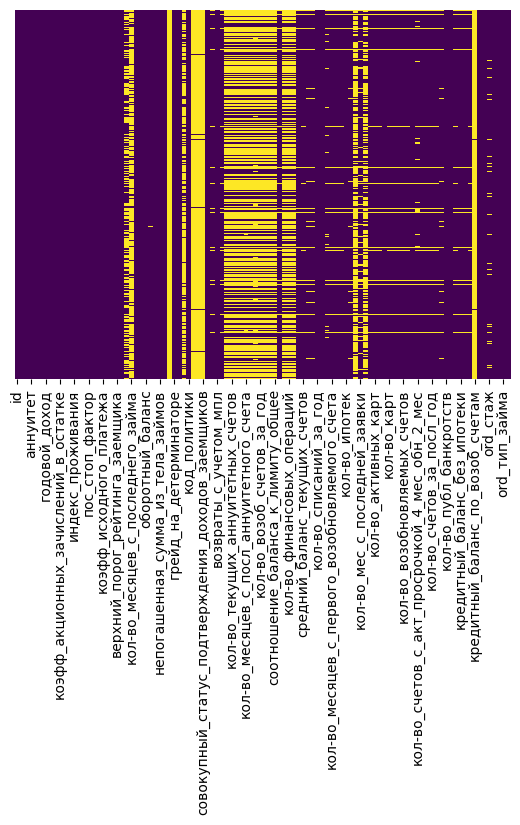

In [331]:
sns.heatmap(test.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [372]:
missing = test.isnull().mean()
cols_to_drop = list(missing[missing > 0.85].index)
for col in cols_to_drop:
    test[f'{col}_есть_данные'] = test[col].notnull().astype(int)

test.drop(cols_to_drop, axis=1, inplace=True)
test.drop('id', axis=1, inplace=True)

In [373]:
num_count = test.select_dtypes(include='number').shape[1]
obj_count = test.select_dtypes(include='object').shape[1]
cat_count = test.select_dtypes(include='category').shape[1]
print('Numeric columns:', num_count)
print('Object columns:', obj_count)
print('Categorical columns:', cat_count)

Numeric columns: 96
Object columns: 6
Categorical columns: 0


In [374]:
obj_cols = test.select_dtypes(include='object').columns
test[obj_cols] = test[obj_cols].fillna('missing').astype(str)
for col in obj_cols:
    test[col] = test[col].astype('category')
categ_cols = test.select_dtypes(include='category').columns.tolist()

In [367]:
oof_preds = np.zeros(len(test))
kf = KFold(n_splits=5, shuffle=True, random_state=42)
final_test_preds = np.zeros(len(test))

print('Результаты кросс-валидации:')
for fold, (train_idx, val_idx) in enumerate(kf.split(test, y_prob)):
    X_train_fold, X_val_fold = test.iloc[train_idx], test.iloc[val_idx]
    y_train_fold, y_val_fold = y_prob.iloc[train_idx], y_prob.iloc[val_idx]
    
    model_reg = CatBoostRegressor(n_estimators=1500,
                                  learning_rate=0.05,
                                  depth=4,
                                  l2_leaf_reg=10,
                                  task_type='GPU',
                                  random_state=42+fold,
                                  verbose=0)

    model_reg.fit(X_train_fold, y_train_fold, 
                  eval_set=(X_val_fold, y_val_fold),
                  cat_features=categ_cols,
                  early_stopping_rounds=50,
                  use_best_model=True)

    oof_preds[val_idx] = model_big.predict(X_val_fold)
    rmse_value = model_reg.get_best_score()['validation']['RMSE']
    print('Фолд', fold+1, 'RMSE:', round(rmse_value, 5))

    final_test_preds += model_reg.predict(test) / kf.n_splits

Результаты кросс-валидации:
Фолд 1 RMSE: 0.00754
Фолд 2 RMSE: 0.00683
Фолд 3 RMSE: 0.00681
Фолд 4 RMSE: 0.00674
Фолд 5 RMSE: 0.00694


In [369]:
final_test_preds = np.clip(final_test_preds, 0.0, 1.0)

submission = pd.DataFrame({
    'id': ids,
    'proba': final_test_preds})

submission.to_csv('submit_soft_labels_final.csv', index=False)

In [382]:
feature_importance = model_reg.get_feature_importance()
feature_names = test.columns

fi_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность (%)': feature_importance
})

fi_df = fi_df.sort_values(by='Важность (%)', ascending=False).reset_index(drop=True)
top_10_features = fi_df.head(10)

print('10 самых важных признаков:')
print(top_10_features.to_string(index=False))

10 самых важных признаков:
                                  Признак  Важность (%)
                              сумма_займа     49.595149
                          лимит_по_картам     41.585536
         кол-во_открытых_счетов_за_2_года      3.893313
             кредитный_баланс_без_ипотеки      1.547335
            процент_счетов_прев_75_лимита      1.097154
суммарная_доступная_сумма_займа_по_картам      0.723702
                              ord_рейтинг      0.411825
                        процентная_ставка      0.411639
                            кол-во_ипотек      0.325642
                            годовой_доход      0.071866
